# Solar filament instance-segmentation training

A self-contained Mask R-CNN baseline for the MAGFiLO Kaggle competition. Run cells in order. All project functions live here; no external `.py` files are required.

**Before a long run:** enable a Kaggle GPU, attach the competition data, review configuration, inspect the split audit and transformed targets, then enable `RUN_TRAINING`. Internet is needed once for pretrained weights and any missing packages. Offline runs can use an attached local backbone state dictionary.

Training settings are provisional. The notebook includes one-fold or five-fold training, checkpoint resume, reference PQ validation, per-station diagnostics, threshold experiments, final retraining, and optional submission export. It does not launch training until you enable it.

**Metric limitation:** the included metric is standard instance PQ with strict IoU > 0.5 matching, averaged over annotation sets and then unique photographs. It is a local reference, not a verified reproduction of the organizer's implementation, edge-case rules, or aggregation. Verify against the [organizer's self-evaluation notebook](https://www.kaggle.com/code/azimahmadzadeh/self-evaluation-notebook) before interpreting scores as competition scores.

## 1. Environment

Install missing dependencies only. Do not replace Kaggle's matched Torch/Torchvision pair. If this cell installs packages, restart the kernel if prompted. `requirements.txt` records the versions actually used.

In [1]:
import importlib.util
import subprocess
import sys

missing = [package for module, package in [
    ('pycocotools', 'pycocotools'), ('sklearn', 'scikit-learn'),
    ('pandas', 'pandas'), ('PIL', 'Pillow'), ('matplotlib', 'matplotlib')
] if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])


In [2]:
import copy
import csv
import hashlib
import importlib.metadata
import json
import math
import random
import re
import time
from collections import defaultdict
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from pycocotools import mask as coco_mask
from sklearn.model_selection import StratifiedGroupKFold
import torch
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet50_Weights
from torchvision.models.detection import maskrcnn_resnet50_fpn


## 2. Configuration

Use `FOLDS=(0,)` first; choose `(0,1,2,3,4)` for cross-validation. Date grouping is only an initial independence assumption. `PURGE_HOURS` removes training observations close to validation times; choose its value after auditing cadence. Exact duplicate files are grouped together across dates.

The backbone uses ImageNet weights; prediction heads start fresh. A local backbone checkpoint must contain a torchvision ResNet-50 state dictionary. Load only trusted model files. `RUN_FINAL_TRAINING` and `RUN_SUBMISSION` are independent opt-ins.

Model upload is enabled by default after a successful training run. Set `kaggle_model_owner` to your Kaggle username before enabling training. `kaggle_upload_checkpoint` can explicitly select an existing trained checkpoint. Otherwise final retraining takes priority; a fold-only run saves the first selected fold's best checkpoint. Distinct fold models need distinct variation names when uploading individually. Set `run_model_upload=False` for an offline-only run.

In [3]:
@dataclass
class Config:
    data_root: str = '/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026'
    output_root: str = '/kaggle/working/solar-filament-training'
    seed: int = 42
    n_folds: int = 5
    folds: tuple = (0,)
    block_days: int = 1
    purge_hours: float = 24.0
    image_size: int = 1024
    batch_size: int = 1
    effective_batch_size: int = 4
    workers: int = 0  # Portable notebook default; increase only after a smoke test.
    epochs: int = 50
    warmup_epochs: int = 2
    patience: int = 10
    backbone_lr: float = 1e-5
    head_lr: float = 1e-4
    weight_decay: float = 1e-4
    horizontal_flip: float = 0.5
    vertical_flip: float = 0.5
    brightness_jitter: float = 0.0
    score_threshold: float = 0.5
    mask_threshold: float = 0.5
    max_detections: int = 100
    amp: bool = True
    pretrained: bool = True
    backbone_weights_path: str = ''
    resume_path: str = ''  # last.pt from the same fold/configuration only.
    run_training: bool = True
    run_threshold_search: bool = False
    run_final_training: bool = False
    final_epochs: int = 30  # Replace using cross-validation; not a validated default.
    run_submission: bool = False
    submission_checkpoint: str = ''  # Set explicitly: fold best.pt or final/model.pt.
    run_model_upload: bool = True  # Runs at the end only if a trained checkpoint exists.
    kaggle_model_owner: str = 'gany24558'  # Your Kaggle username; set before enabling training.
    kaggle_model_slug: str = 'solar-filament-segmentation'
    kaggle_model_variation: str = 'mask-rcnn-resnet50-fpn'
    kaggle_model_license: str = ''  # Optional Kaggle license name; omission uses Kaggle defaults.
    kaggle_upload_checkpoint: str = ''  # Explicit override; otherwise use this run's trained model.
    kaggle_version_notes: str = 'Mask R-CNN solar filament training checkpoint'


CFG = Config()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| Torch:', torch.__version__, '| Torchvision:', torchvision.__version__)


Device: cuda | Torch: 2.11.0+cu128 | Torchvision: 0.26.0+cu128


### Reproducible random seeds

Seed Python, NumPy and Torch. Exact reproducibility can still depend on GPU kernels and library versions.

In [4]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False


### Validate configuration

Fail early on invalid settings rather than silently changing the effective batch size.

In [5]:
def validate_config(cfg):
    assert cfg.n_folds >= 2 and cfg.block_days >= 1
    assert cfg.image_size >= 64 and cfg.epochs >= 1 and cfg.final_epochs >= 1
    assert cfg.batch_size >= 1 and cfg.effective_batch_size % cfg.batch_size == 0
    assert cfg.purge_hours >= 0 and 0 <= cfg.brightness_jitter < 1
    assert all(0 <= value <= 1 for value in [cfg.horizontal_flip, cfg.vertical_flip,
                                              cfg.score_threshold, cfg.mask_threshold])
    assert all(0 <= fold < cfg.n_folds for fold in cfg.folds)
    assert len(set(cfg.folds)) == len(cfg.folds)

    if cfg.run_model_upload and (cfg.run_training or cfg.run_final_training or cfg.kaggle_upload_checkpoint):
        for value in [cfg.kaggle_model_owner, cfg.kaggle_model_slug, cfg.kaggle_model_variation]:
            if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]*', value):
                raise ValueError('Set valid Kaggle owner, model slug and variation before starting training')


### Create the run directory

Record configuration and dependency versions. Keep outputs outside the attached read-only data directory.

In [6]:
def prepare_run(cfg):
    validate_config(cfg)
    seed_everything(cfg.seed)
    output = Path(cfg.output_root)
    output.mkdir(parents=True, exist_ok=True)
    (output / 'config.json').write_text(json.dumps(asdict(cfg), indent=2))
    packages = ['torch', 'torchvision', 'numpy', 'pandas', 'Pillow',
                'pycocotools', 'scikit-learn', 'matplotlib']
    versions = [f'{name}=={importlib.metadata.version(name)}' for name in packages]
    (output / 'requirements.txt').write_text('\n'.join(versions) + '\n')
    return output


In [7]:
OUTPUT = prepare_run(CFG)


## 3. Source photographs and annotation sets

The dataset has several image records for some photographs. These records are alternative annotator sets, not extra independent images. We retain all sets, choose one at random per training visit, and never union alternative annotations into one target.

### Read and audit the annotation index

Require exactly one annotation JSON; check unique IDs, dimensions, file links and orphan annotations.

In [8]:
def load_catalog(cfg):
    root = Path(cfg.data_root)
    files = sorted((root / 'train').glob('*.json'))
    if len(files) != 1:
        raise ValueError(f'Expected one training JSON, found {len(files)} in {root}')
    raw = json.loads(files[0].read_text())
    images = {item['id']: item for item in raw['images']}
    assert len(images) == len(raw['images']), 'Duplicate JSON image IDs'
    assert len({a['id'] for a in raw['annotations']}) == len(raw['annotations'])
    annotations = defaultdict(list)
    for annotation in raw['annotations']:
        assert annotation['image_id'] in images, 'Orphan annotation'
        annotations[annotation['image_id']].append(annotation)
    records = defaultdict(list)
    for record in images.values():
        name = record['file_name']
        assert Path(name).name == name, f'Expected basename: {name}'
        path = root / 'train' / 'train_images' / name
        assert path.is_file(), f'Missing image: {path}'
        with Image.open(path) as image:
            assert image.size == (record['width'], record['height'])
        records[name].append(record)
    print('Unique referenced photographs:', len(records), '| Annotation sets:', len(images))
    print('Instances:', len(raw['annotations']), '| Empty annotation sets:',
          sum(not annotations[key] for key in images))
    return dict(records), dict(annotations)


### Hash source files

Hash raw bytes to identify exact duplicate files. This does not detect recompressed or visually similar images.

In [9]:
def file_hash(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


### Build photograph metadata

Parse UTC timestamps with a strict filename pattern. Unparsed files cause an error instead of disappearing from folds.

In [10]:
def build_metadata(records, cfg):
    rows = []
    for name in sorted(records):
        match = re.fullmatch(r'(\d{14})([A-Za-z]{2})\.(?:jpg|jpeg)', name)
        if match is None:
            raise ValueError(f'Unrecognized image filename: {name}')
        path = Path(cfg.data_root) / 'train' / 'train_images' / name
        rows.append({'filename': name, 'timestamp': pd.to_datetime(match[1], utc=True),
                     'station': match[2], 'sha256': file_hash(path)})
    frame = pd.DataFrame(rows)
    frame['time_block'] = frame.timestamp.dt.as_unit('ns').astype('int64') // (cfg.block_days * 86400 * 10**9)
    return frame


### Unite duplicate and temporal groups

A duplicate bridging two time blocks joins both blocks. This preserves both constraints when allocating folds.

In [11]:
def unite_groups(frame):
    parent = {block: block for block in frame.time_block.unique()}
    # Find roots inline so this cell defines one method only.
    for _, duplicates in frame.groupby('sha256'):
        roots = []
        for block in duplicates.time_block:
            while parent[block] != block:
                block = parent[block]
            roots.append(block)
        for root in roots[1:]:
            parent[root] = roots[0]
    groups = []
    for block in frame.time_block:
        while parent[block] != block:
            block = parent[block]
        groups.append(str(block))
    return frame.assign(group=groups)


### Assign grouped folds

Station stratification is approximate. Inspect the resulting table; never split a group to improve station balance.

In [12]:
def assign_folds(frame, cfg):
    assert frame.group.nunique() >= cfg.n_folds, 'Too few independent groups'
    splitter = StratifiedGroupKFold(cfg.n_folds, shuffle=True, random_state=cfg.seed)
    frame = frame.copy()
    frame['fold'] = -1
    for fold, (_, valid) in enumerate(splitter.split(frame, frame.station, frame.group)):
        frame.loc[valid, 'fold'] = fold
    assert frame.groupby('group').fold.nunique().max() == 1
    assert frame.groupby('sha256').fold.nunique().max() == 1
    return frame


### Measure nearest validation times

Return the nearest timestamp gap for each training photograph using a sorted search, not a large all-pairs matrix.

In [13]:
def nearest_gaps_hours(train, valid):
    reference = np.sort(valid.timestamp.dt.as_unit('ns').astype('int64').to_numpy())
    values = train.timestamp.dt.as_unit('ns').astype('int64').to_numpy()
    positions = np.searchsorted(reference, values)
    left = reference[np.clip(positions - 1, 0, len(reference) - 1)]
    right = reference[np.clip(positions, 0, len(reference) - 1)]
    return np.minimum(abs(values - left), abs(values - right)) / (3600 * 10**9)


### Apply the temporal exclusion gap

Purge whole training groups if any member lies within the configured validation gap. This can reduce training coverage substantially.

In [14]:
def split_fold(frame, fold, cfg):
    valid = frame.loc[frame.fold == fold].copy()
    train = frame.loc[frame.fold != fold].copy()
    gaps = nearest_gaps_hours(train, valid)
    blocked = set(train.loc[gaps <= cfg.purge_hours, 'group'])
    train = train.loc[~train.group.isin(blocked)].copy()
    assert len(train) and len(valid), 'Temporal purge left an empty split'
    assert not set(train.group) & set(valid.group)
    assert not set(train.sha256) & set(valid.sha256)
    gap = float(nearest_gaps_hours(train, valid).min())
    assert gap > cfg.purge_hours
    print(f'Fold {fold}: train={len(train)}, valid={len(valid)}, nearest gap={gap:.1f} h')
    return train, valid


In [15]:
RECORDS, ANNOTATIONS = load_catalog(CFG)
META = assign_folds(unite_groups(build_metadata(RECORDS, CFG)), CFG)
META.to_csv(OUTPUT / 'fold_assignments.csv', index=False)
print(pd.crosstab(META.fold, META.station))
for fold in CFG.folds:
    train_frame, valid_frame = split_fold(META, fold, CFG)
    train_frame.to_csv(OUTPUT / f'fold_{fold}_train.csv', index=False)
    valid_frame.to_csv(OUTPUT / f'fold_{fold}_valid.csv', index=False)


Unique referenced photographs: 707 | Annotation sets: 1154
Instances: 8199 | Empty annotation sets: 0
station  Bh  Ch  Lh  Mh  Th  Uh
fold                           
0        27  26  18  21  25  27
1        25  27  24  29  23  13
2        25  24  23  26  29  18
3        20  22  34  29  18  17
4        21  26  28  20  15  27
Fold 0: train=528, valid=144, nearest gap=24.0 h


## 4. Masks, paired transforms and targets

Decode polygons, uncompressed RLE and compressed RLE. Resize masks using nearest-neighbor interpolation, and images using bilinear interpolation. Count masks lost through resizing: they must not disappear unnoticed. Training boxes come from the transformed masks, including valid one-pixel-wide objects.

Inputs remain in `[0,1]`; Torchvision's internal transform performs backbone normalization. We explicitly set its resize limits to avoid its default 800-pixel resize overriding our 1024-pixel input.

### Decode one annotation mask

Invalid segmentation representations raise errors; they are not silently turned into background.

In [16]:
def decode_annotation(annotation, height, width):
    segment = annotation['segmentation']
    if isinstance(segment, list):
        if not segment:
            raise ValueError(f"Empty polygon: {annotation['id']}")
        rle = coco_mask.merge(coco_mask.frPyObjects(segment, height, width))
    elif isinstance(segment, dict):
        rle = dict(segment)
        if isinstance(rle['counts'], list):
            rle = coco_mask.frPyObjects(rle, height, width)
        elif isinstance(rle['counts'], str):
            rle['counts'] = rle['counts'].encode('ascii')
    else:
        raise ValueError(f"Invalid segmentation: {annotation['id']}")
    mask = coco_mask.decode(rle)
    assert mask.shape == (height, width), 'Mask shape mismatch'
    return (mask > 0).astype(np.uint8)


### Load a photograph

Repeat the grayscale channel without treating the image as real color data.

In [17]:
def load_image(path, size):
    with Image.open(path) as source:
        gray = source.convert('L')
        original_size = (gray.height, gray.width)
        resized = gray.resize((size, size), Image.Resampling.BILINEAR)
        array = np.array(resized, dtype=np.float32) / 255.0
    return torch.from_numpy(array).unsqueeze(0).repeat(3, 1, 1), original_size


### Resize one complete annotation set

Keep empty annotation sets valid. Nonempty masks that vanish at this resolution are counted for the audit.

In [18]:
def load_masks(record, annotations, size):
    masks, lost = [], 0
    for annotation in annotations.get(record['id'], []):
        mask = decode_annotation(annotation, record['height'], record['width'])
        if not mask.any():
            raise ValueError(f"Empty original mask: {annotation['id']}")
        resized = np.array(Image.fromarray(mask).resize((size, size), Image.Resampling.NEAREST))
        if resized.any():
            masks.append(resized)
        else:
            lost += 1
    array = np.stack(masks) if masks else np.zeros((0, size, size), dtype=np.uint8)
    return torch.from_numpy(array), lost


### Apply paired augmentation

Flips preserve instance identities. Brightness jitter is optional and off by default.

In [19]:
def augment_pair(image, masks, cfg):
    if random.random() < cfg.horizontal_flip:
        image, masks = image.flip(-1), masks.flip(-1)
    if random.random() < cfg.vertical_flip:
        image, masks = image.flip(-2), masks.flip(-2)
    if cfg.brightness_jitter:
        factor = random.uniform(1 - cfg.brightness_jitter, 1 + cfg.brightness_jitter)
        image = (image * factor).clamp(0, 1)
    return image, masks


### Build instance detection targets

Use half-open maximum coordinates so thin objects have strictly positive box width and height.

In [20]:
def make_target(masks, image_index):
    boxes = []
    for mask in masks:
        y, x = torch.where(mask > 0)
        boxes.append([x.min().item(), y.min().item(), x.max().item() + 1, y.max().item() + 1])
    boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
    return {'boxes': boxes, 'labels': torch.ones(len(masks), dtype=torch.int64),
            'masks': masks.to(torch.uint8), 'image_id': torch.tensor(image_index),
            'area': masks.flatten(1).sum(1).float(),
            'iscrowd': torch.zeros(len(masks), dtype=torch.int64)}


### Photograph dataset

The three Dataset protocol methods are defined in separate cells for readability. The final class binds them together without hiding any loading or augmentation logic. Validation uses a deterministic first target only for visualization; scoring uses every original annotation set separately.

In [21]:
def dataset_init(self, names, records, annotations, cfg, training):
    self.names, self.records = (list(names), records)
    self.annotations, self.cfg, self.training = (annotations, cfg, training)

In [22]:
def dataset_length(self):
    return len(self.names)

In [23]:
def dataset_item(self, index):
    name = self.names[index]
    choices = self.records[name]
    record = random.choice(choices) if self.training else choices[0]
    path = Path(self.cfg.data_root) / 'train' / 'train_images' / name
    image, _ = load_image(path, self.cfg.image_size)
    masks, _ = load_masks(record, self.annotations, self.cfg.image_size)
    if self.training:
        image, masks = augment_pair(image, masks, self.cfg)
    return (image, make_target(masks, index))

In [24]:
class FilamentDataset(Dataset):
    __init__ = dataset_init
    __len__ = dataset_length
    __getitem__ = dataset_item

### Collate variable instance counts

Detection models receive lists of images and targets rather than one stacked target tensor.

In [25]:
def collate_detection(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)


### Audit mask survival

Run this before training. Increasing resolution is preferable if important small annotations disappear.

In [26]:
def audit_mask_survival(records, annotations, cfg):
    total, lost = 0, 0
    for choices in records.values():
        for record in choices:
            _, missing = load_masks(record, annotations, cfg.image_size)
            lost += missing
            total += len(annotations.get(record['id'], []))
    print(f'Masks lost at {cfg.image_size}px: {lost}/{total}')
    return {'total_masks': total, 'lost_masks': lost, 'input_size': cfg.image_size}


In [27]:
SURVIVAL = audit_mask_survival(RECORDS, ANNOTATIONS, CFG)
(OUTPUT / 'mask_survival.json').write_text(json.dumps(SURVIVAL, indent=2))


Masks lost at 1024px: 0/8199


66

### Display an example with separate instance contours

This checks transformed targets before spending GPU time. Colors distinguish objects, not chirality.

In [28]:
def show_targets(dataset, index=0):
    image, target = dataset[index]
    plt.figure(figsize=(9, 9))
    plt.imshow(image[0], cmap='gray')
    colors = plt.cm.tab20(np.linspace(0, 1, max(1, len(target['masks']))))
    for mask, color in zip(target['masks'], colors):
        if mask.any():
            plt.contour(mask.numpy(), levels=[0.5], colors=[color])
    plt.title(f'{dataset.names[index]} | {len(target["masks"])} instances')
    plt.axis('off')
    plt.show()


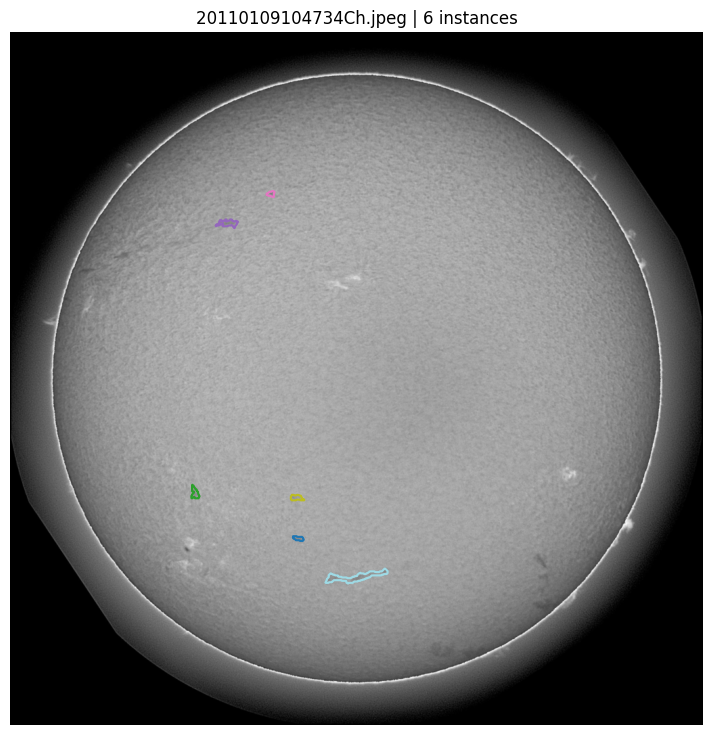

In [29]:
EXAMPLE = FilamentDataset(META.filename, RECORDS, ANNOTATIONS, CFG, training=True)
show_targets(EXAMPLE)


## 5. Model and optimization

Only segmentation-derived boxes and the filament class are used. The internal Mask R-CNN transform normalizes once. Mixed precision is enabled on CUDA; CPU remains supported for small smoke tests. These settings do not imply full training will be practical on CPU.

### Construct Mask R-CNN

ImageNet backbone initialization downloads weights once unless a local state dictionary is supplied. No pretrained weights are required when reloading a complete trained checkpoint.

In [30]:
def build_model(cfg, initialize=True):
    weights = ResNet50_Weights.DEFAULT if initialize and cfg.pretrained and not cfg.backbone_weights_path else None
    model = maskrcnn_resnet50_fpn(
        weights=None, weights_backbone=weights, num_classes=2,
        min_size=cfg.image_size, max_size=cfg.image_size,
        box_score_thresh=0.0, box_detections_per_img=cfg.max_detections,
        trainable_backbone_layers=5)
    if initialize and cfg.backbone_weights_path:
        state = torch.load(cfg.backbone_weights_path, map_location='cpu', weights_only=True)
        model.backbone.body.load_state_dict({k: v for k, v in state.items() if not k.startswith('fc.')})
    return model.to(DEVICE)


### Create optimizer groups

Fine-tune the backbone more slowly than the feature pyramid and detection heads.

In [31]:
def build_optimizer(model, cfg):
    backbone, heads = [], []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            (backbone if name.startswith('backbone.body.') else heads).append(parameter)
    return torch.optim.AdamW([
        {'params': backbone, 'lr': cfg.backbone_lr},
        {'params': heads, 'lr': cfg.head_lr}], weight_decay=cfg.weight_decay)


### Epoch learning-rate multiplier

Warm up, then decay smoothly. The scheduler is restored when resuming.

In [32]:
def lr_multiplier(epoch, cfg):
    if epoch < cfg.warmup_epochs:
        return (epoch + 1) / max(1, cfg.warmup_epochs)
    progress = (epoch - cfg.warmup_epochs) / max(1, cfg.epochs - cfg.warmup_epochs - 1)
    return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))


### Train one epoch

Accumulate image-weighted loss sums, then divide gradients by the actual image count in each update. This handles a short final accumulation group correctly. Nonfinite losses abort with an error.

In [33]:
def train_epoch(model, loader, optimizer, scaler, cfg):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    loss_sum, image_count, accumulated = 0.0, 0, 0
    for step, (images, targets) in enumerate(loader):
        images = [image.to(DEVICE) for image in images]
        targets = [{key: value.to(DEVICE) for key, value in target.items()} for target in targets]
        with torch.autocast(device_type=DEVICE.type, enabled=cfg.amp and DEVICE.type == 'cuda'):
            losses = model(images, targets)
            loss = sum(losses.values())
        if not torch.isfinite(loss):
            raise FloatingPointError({key: value.item() for key, value in losses.items()})
        count = len(images)
        scaler.scale(loss * count).backward()
        accumulated += count
        loss_sum += loss.item() * count
        image_count += count
        if accumulated >= cfg.effective_batch_size or step + 1 == len(loader):
            scaler.unscale_(optimizer)
            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.div_(accumulated)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            accumulated = 0
    return loss_sum / max(1, image_count)


## 6. Original-resolution predictions and reference PQ

Predictions are resized as probabilities before binarization. Confidence-ordered pixel ownership makes returned masks nonoverlapping; treat this as a post-processing choice to validate. No component splitting or size filtering is applied. RLE storage avoids keeping many original-resolution masks in GPU memory.

The local reference matches pairs with IoU strictly above 0.5. For rare ambiguous overlaps it uses descending-IoU greedy matching. Empty/empty sets receive 1.0. These choices must be checked against the host evaluator. Scores are explicitly named `reference_pq` throughout.

### Encode a binary mask

COCO compressed RLE uses Fortran-order arrays. Store counts as text for CSV and JSON export.

In [34]:
def encode_mask(mask):
    encoded = coco_mask.encode(np.asfortranarray(mask.astype(np.uint8)))
    return {'size': list(encoded['size']), 'counts': encoded['counts'].decode('ascii')}


### Restore byte counts for COCO utilities

Keep JSON-friendly RLE outside metric calculations.

In [35]:
def native_rle(encoded):
    return {'size': encoded['size'], 'counts': encoded['counts'].encode('ascii')}


### Post-process one prediction

Filter detections, upsample one mask at a time, and resolve overlaps by detection confidence.

In [36]:
def prediction_rles(prediction, original_size, cfg):
    height, width = original_size
    occupied = np.zeros((height, width), dtype=bool)
    result = []
    for index in prediction['scores'].argsort(descending=True).tolist():
        if prediction['scores'][index].item() < cfg.score_threshold:
            continue
        probability = prediction['masks'][index:index + 1].float()
        restored = F.interpolate(probability, size=(height, width), mode='bilinear', align_corners=False)
        mask = (restored[0, 0].cpu().numpy() >= cfg.mask_threshold) & ~occupied
        if mask.any():
            result.append(encode_mask(mask))
            occupied |= mask
    return result


### Predict one photograph

Includes preprocessing and mask post-processing in the timing; weights remain loaded.

In [37]:
@torch.inference_mode()
def predict_image(model, path, cfg):
    image, shape = load_image(path, cfg.image_size)
    prediction = model([image.to(DEVICE)])[0]
    return prediction_rles(prediction, shape, cfg)


### Reference instance PQ

Return matched count, misses and false positives as well as PQ. This is not claimed to reproduce Kaggle exactly.

In [38]:
def reference_pq(predicted, truth):
    n_pred, n_true = len(predicted), len(truth)
    matches, overlap_sum = 0, 0.0
    used_pred, used_true = set(), set()
    if n_pred and n_true:
        ious = coco_mask.iou([native_rle(r) for r in predicted],
                             [native_rle(r) for r in truth], [0] * n_true)
        candidates = np.argwhere(ious > 0.5)
        ordered = sorted(candidates.tolist(), key=lambda pair: ious[tuple(pair)], reverse=True)
        for pred, target in ordered:
            if pred not in used_pred and target not in used_true:
                used_pred.add(pred)
                used_true.add(target)
                matches += 1
                overlap_sum += float(ious[pred, target])
    fp, fn = n_pred - matches, n_true - matches
    denominator = matches + 0.5 * fp + 0.5 * fn
    return {'reference_pq': overlap_sum / denominator if denominator else 1.0,
            'tp': matches, 'fp': fp, 'fn': fn}


### Evaluate every annotation set

Predict once per photograph. Average alternative-annotator results within each photograph before averaging photographs.

In [39]:
def evaluate_model(model, frame, records, annotations, cfg):
    model.eval()
    rows = []
    start = time.perf_counter()
    for row in frame.itertuples():
        path = Path(cfg.data_root) / 'train' / 'train_images' / row.filename
        predicted = predict_image(model, path, cfg)
        for record in records[row.filename]:
            truth = [encode_mask(decode_annotation(a, record['height'], record['width']))
                     for a in annotations.get(record['id'], [])]
            metrics = reference_pq(predicted, truth)
            rows.append({'filename': row.filename, 'station': row.station,
                         'annotation_set': record['id'], **metrics})
    table = pd.DataFrame(rows)
    by_image = table.groupby(['filename', 'station'], as_index=False).reference_pq.mean()
    metrics = {'reference_pq': float(by_image.reference_pq.mean()),
               'seconds_per_image': (time.perf_counter() - start) / len(frame)}
    return metrics, table, by_image


## 7. Checkpointing and training orchestration

`last.pt` includes optimizer, scaler, scheduler and random states for resuming the same fold. `best.pt` records the highest local reference PQ at the configured thresholds. Resume checks the fold, training configuration and input fingerprint. Changing data, folds, thresholds or training settings requires a new run directory.

Threshold tuning and repeated checkpoint selection use validation data and can bias its score upward. Use an additional holdout or nested validation for a final unbiased estimate. The five-fold results here are development cross-validation, not a guaranteed unbiased estimate.

### Fingerprint data and folds

Include annotation contents and source hashes to detect changed inputs during resume.

In [40]:
def input_fingerprint(frame, records, annotations):
    payload = {'metadata': frame[['filename', 'sha256', 'group', 'fold']].to_dict('records'),
               'records': records, 'annotations': annotations}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


### Save a restartable checkpoint

Write through a temporary file so interrupted saves do not replace a good checkpoint.

In [41]:
def save_checkpoint(path, model, optimizer, scheduler, scaler, epoch, best, stale, history, cfg, fold, fingerprint):
    state = {'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
             'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
             'epoch': epoch, 'best': best, 'stale': stale, 'history': history,
             'config': asdict(cfg), 'fold': fold, 'fingerprint': fingerprint,
             'python_rng': random.getstate(), 'numpy_rng': np.random.get_state(),
             'torch_rng': torch.get_rng_state(),
             'cuda_rng': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}
    temporary = path.with_suffix('.tmp')
    torch.save(state, temporary)
    temporary.replace(path)


### Resume a trusted local checkpoint

This loads Python RNG state using pickle; only load your own trusted checkpoints.

In [42]:
def restore_checkpoint(path, model, optimizer, scheduler, scaler, cfg, fold, fingerprint):
    state = torch.load(path, map_location='cpu', weights_only=False)
    assert state['fold'] == fold and state['fingerprint'] == fingerprint
    ignored = {'resume_path', 'run_training', 'run_threshold_search', 'run_final_training',
               'run_submission', 'submission_checkpoint', 'output_root',
               'run_model_upload', 'kaggle_model_owner', 'kaggle_model_slug',
               'kaggle_model_variation', 'kaggle_model_license', 'kaggle_upload_checkpoint',
               'kaggle_version_notes'}
    for key, value in asdict(cfg).items():
        if key not in ignored:
            assert state['config'][key] == value, f'Resume setting changed: {key}'
    model.load_state_dict(state['model'])
    optimizer.load_state_dict(state['optimizer'])
    scheduler.load_state_dict(state['scheduler'])
    scaler.load_state_dict(state['scaler'])
    random.setstate(state['python_rng'])
    np.random.set_state(state['numpy_rng'])
    torch.set_rng_state(state['torch_rng'])
    if torch.cuda.is_available() and state['cuda_rng'] is not None:
        torch.cuda.set_rng_state_all(state['cuda_rng'])
    return state


### Train one fold

A unique photograph appears once per epoch, with one randomly chosen annotator set. Keep all per-epoch and per-annotator diagnostics on disk.

In [43]:
def fit_fold(fold, frame, records, annotations, cfg):
    seed_everything(cfg.seed + fold)
    train, valid = split_fold(frame, fold, cfg)
    folder = Path(cfg.output_root) / f'fold_{fold}'
    folder.mkdir(parents=True, exist_ok=True)
    if (folder / 'last.pt').exists() and not cfg.resume_path:
        raise FileExistsError(f'{folder} already contains a run; resume explicitly or use a new output root')
    dataset = FilamentDataset(train.filename, records, annotations, cfg, training=True)
    loader = DataLoader(dataset, batch_size=cfg.batch_size, shuffle=True,
                        num_workers=cfg.workers, collate_fn=collate_detection)
    model = build_model(cfg, initialize=not bool(cfg.resume_path))
    optimizer = build_optimizer(model, cfg)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda epoch: lr_multiplier(epoch, cfg))
    scaler = torch.amp.GradScaler('cuda', enabled=cfg.amp and DEVICE.type == 'cuda')
    fingerprint = input_fingerprint(frame, records, annotations)
    start, best, stale, history = 0, -1.0, 0, []
    if cfg.resume_path:
        state = restore_checkpoint(cfg.resume_path, model, optimizer, scheduler, scaler, cfg, fold, fingerprint)
        start, best, stale, history = state['epoch'] + 1, state['best'], state['stale'], state['history']
    for epoch in range(start, cfg.epochs):
        if stale >= cfg.patience:
            break
        loss = train_epoch(model, loader, optimizer, scaler, cfg)
        metrics, details, images = evaluate_model(model, valid, records, annotations, cfg)
        improved = metrics['reference_pq'] > best
        best, stale = (metrics['reference_pq'], 0) if improved else (best, stale + 1)
        history.append({'epoch': epoch + 1, 'train_loss': loss, **metrics})
        scheduler.step()
        details.to_csv(folder / 'latest_annotation_metrics.csv', index=False)
        images.groupby('station').reference_pq.agg(['mean', 'count']).to_csv(folder / 'latest_station_metrics.csv')
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        save_checkpoint(folder / 'last.pt', model, optimizer, scheduler, scaler,
                        epoch, best, stale, history, cfg, fold, fingerprint)
        if improved:
            save_checkpoint(folder / 'best.pt', model, optimizer, scheduler, scaler,
                            epoch, best, stale, history, cfg, fold, fingerprint)
            details.to_csv(folder / 'best_annotation_metrics.csv', index=False)
        print(f'Fold {fold} | epoch {epoch + 1} | loss {loss:.4f} | reference PQ {metrics["reference_pq"]:.4f}')
    del model, optimizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return {'fold': fold, 'best_reference_pq': best}


### Start the selected folds

Set `CFG.run_training=True` in the configuration cell and rerun the notebook. Begin with one fold and inspect the first epoch. Five-fold training repeats the complete model fit five times. Do not interpret a successful cell definition as a completed training run.

In [44]:
FOLD_RESULTS = []
if CFG.run_training:
    if CFG.resume_path and len(CFG.folds) != 1:
        raise ValueError('Resume one fold at a time')
    for fold in CFG.folds:
        FOLD_RESULTS.append(fit_fold(fold, META, RECORDS, ANNOTATIONS, CFG))
    summary = pd.DataFrame(FOLD_RESULTS)
    summary.to_csv(OUTPUT / 'cross_validation.csv', index=False)
    print(summary)
    print('Mean development reference PQ:', summary.best_reference_pq.mean())
    if len(summary) > 1:
        print('Fold standard deviation:', summary.best_reference_pq.std())
else:
    print('Training disabled. Review audits, then enable CFG.run_training.')


Fold 0: train=528, valid=144, nearest gap=24.0 h
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 262MB/s]


Fold 0 | epoch 1 | loss 1.5182 | reference PQ 0.0819
Fold 0 | epoch 2 | loss 1.0427 | reference PQ 0.1439
Fold 0 | epoch 3 | loss 1.0200 | reference PQ 0.1962
Fold 0 | epoch 4 | loss 0.9943 | reference PQ 0.1829
Fold 0 | epoch 5 | loss 0.9778 | reference PQ 0.2324
Fold 0 | epoch 6 | loss 0.9460 | reference PQ 0.2297
Fold 0 | epoch 7 | loss 0.9241 | reference PQ 0.2192
Fold 0 | epoch 8 | loss 0.9052 | reference PQ 0.2200
Fold 0 | epoch 9 | loss 0.9024 | reference PQ 0.2525
Fold 0 | epoch 10 | loss 0.8771 | reference PQ 0.2401
Fold 0 | epoch 11 | loss 0.8782 | reference PQ 0.2524
Fold 0 | epoch 12 | loss 0.8702 | reference PQ 0.2698
Fold 0 | epoch 13 | loss 0.8503 | reference PQ 0.2750
Fold 0 | epoch 14 | loss 0.8477 | reference PQ 0.2600
Fold 0 | epoch 15 | loss 0.8349 | reference PQ 0.2730
Fold 0 | epoch 16 | loss 0.8217 | reference PQ 0.2547
Fold 0 | epoch 17 | loss 0.8145 | reference PQ 0.2540
Fold 0 | epoch 18 | loss 0.8089 | reference PQ 0.2565
Fold 0 | epoch 19 | loss 0.7875 | ref

### Load trained weights for evaluation

Load only the model state after reading your trusted checkpoint. Initialization does not download pretrained weights.

In [45]:
def load_trained_model(path, cfg):
    state = torch.load(path, map_location='cpu', weights_only=False)
    assert state['config']['image_size'] == cfg.image_size, 'Input resolution differs from checkpoint'
    model = build_model(cfg, initialize=False)
    model.load_state_dict(state['model'])
    return model.eval()


## 8. Optional threshold experiment

This small grid reruns inference and can be slow. It changes thresholds only; it does not retrain. Scores on the tuning fold are development scores. Freeze chosen thresholds before measuring on an independent holdout. Compare flips, resolution and contrast as separate training runs with the same saved fold manifest.

### Compare detection and mask thresholds

Use the best checkpoint of the first selected fold. Store the grid instead of silently changing production settings.

In [46]:
def threshold_search(cfg, frame, records, annotations):
    fold = cfg.folds[0]
    _, valid = split_fold(frame, fold, cfg)
    model = load_trained_model(Path(cfg.output_root) / f'fold_{fold}' / 'best.pt', cfg)
    rows = []
    for score in [0.3, 0.5, 0.7]:
        for threshold in [0.4, 0.5, 0.6]:
            trial = copy.copy(cfg)
            trial.score_threshold, trial.mask_threshold = score, threshold
            metrics, _, _ = evaluate_model(model, valid, records, annotations, trial)
            rows.append({'score_threshold': score, 'mask_threshold': threshold, **metrics})
    table = pd.DataFrame(rows).sort_values('reference_pq', ascending=False)
    table.to_csv(Path(cfg.output_root) / 'threshold_search.csv', index=False)
    return table


In [47]:
if CFG.run_threshold_search:
    display(threshold_search(CFG, META, RECORDS, ANNOTATIONS))


## 9. Final retraining

Choose `final_epochs` from the validation histories, then enable this stage. It fits all unique training photographs with no validation-based checkpoint selection. The final duration is fixed in advance. This is a fresh fit, not an ensemble. A final model has no honest training-set PQ estimate of generalization.

### Fit all training photographs

Save a restartable final checkpoint after each epoch. This stage currently starts fresh and refuses to overwrite a previous final run.

In [48]:
def fit_final(frame, records, annotations, cfg):
    final = copy.copy(cfg)
    final.epochs = cfg.final_epochs
    seed_everything(cfg.seed)
    folder = Path(cfg.output_root) / 'final'
    folder.mkdir(parents=True, exist_ok=True)
    if (folder / 'model.pt').exists():
        raise FileExistsError('Final model already exists; choose a new output root')
    dataset = FilamentDataset(frame.filename, records, annotations, final, training=True)
    loader = DataLoader(dataset, batch_size=final.batch_size, shuffle=True,
                        num_workers=final.workers, collate_fn=collate_detection)
    model = build_model(final)
    optimizer = build_optimizer(model, final)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda epoch: lr_multiplier(epoch, final))
    scaler = torch.amp.GradScaler('cuda', enabled=final.amp and DEVICE.type == 'cuda')
    history = []
    fingerprint = input_fingerprint(frame, records, annotations)
    for epoch in range(final.epochs):
        loss = train_epoch(model, loader, optimizer, scaler, final)
        scheduler.step()
        history.append({'epoch': epoch + 1, 'train_loss': loss})
        save_checkpoint(folder / 'model.pt', model, optimizer, scheduler, scaler,
                        epoch, -1.0, 0, history, final, 'all', fingerprint)
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        print(f'Final fit | epoch {epoch + 1} | loss {loss:.4f}')
    return folder / 'model.pt'


In [49]:
if CFG.run_final_training:
    FINAL_CHECKPOINT = fit_final(META, RECORDS, ANNOTATIONS, CFG)
    print('Final model:', FINAL_CHECKPOINT)


## 10. Optional test prediction and submission

Set an explicit `submission_checkpoint` and enable `run_submission`. Thresholds are read from configuration, so freeze them before export. Use only the supplied test H-alpha images. Each nonempty predicted instance becomes one CSV row. A test photograph with no predictions produces no rows, but appears in the coverage log. This stage only writes a competition CSV. The separate model-upload stage below uploads trained weights, not competition submissions.

Each RLE is decoded to verify an exact round trip. Original coordinates are taken from each input image; competition images must be 2048 × 2048. The checkpoint, configuration, fold manifests, this notebook and recorded dependency versions form the reproduction package.

### Verify an encoded mask

Check dimensions, nonempty content and compressed encoding stability.

In [50]:
def verify_rle(encoded, expected_size):
    decoded = coco_mask.decode(native_rle(encoded))
    assert tuple(decoded.shape) == tuple(expected_size)
    assert decoded.any()
    again = encode_mask(decoded)
    assert again == encoded, 'RLE round-trip mismatch'


### Write the submission CSV

Stream results image by image, write through a temporary file, and record complete image coverage separately.

In [51]:
def export_submission(cfg):
    if not cfg.submission_checkpoint:
        raise ValueError('Set submission_checkpoint explicitly')
    model = load_trained_model(cfg.submission_checkpoint, cfg)
    paths = sorted(path for path in (Path(cfg.data_root) / 'test' / 'test_images').iterdir()
                   if path.suffix.lower() in {'.jpg', '.jpeg'})
    assert paths and len({path.stem for path in paths}) == len(paths)
    destination = Path(cfg.output_root) / 'submission.csv'
    temporary = destination.with_suffix('.tmp')
    coverage = []
    with open(temporary, 'w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=['filament_id', 'segmentation_rle'])
        writer.writeheader()
        for path in paths:
            with Image.open(path) as image:
                assert image.size == (2048, 2048), f'Unexpected dimensions: {path.name}'
            predicted = predict_image(model, path, cfg)
            for index, encoded in enumerate(predicted, 1):
                verify_rle(encoded, (2048, 2048))
                writer.writerow({'filament_id': f'{path.stem}_{index}',
                                 'segmentation_rle': encoded['counts']})
            coverage.append({'filename': path.name, 'predicted_instances': len(predicted)})
    temporary.replace(destination)
    pd.DataFrame(coverage).to_csv(Path(cfg.output_root) / 'test_coverage.csv', index=False)
    (Path(cfg.output_root) / 'submission_config.json').write_text(json.dumps(asdict(cfg), indent=2))
    return destination


In [52]:
if CFG.run_submission:
    print('Submission saved:', export_submission(CFG))


## References and interpretation

- [Training strategy](https://github.com/gany-c/solar-filament-segmentation/blob/main/training/data_splitting_and_partitioning_strategy.md)
- [Torchvision Mask R-CNN input, targets and weights](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.detection.maskrcnn_resnet50_fpn.html)
- [Competition overview and evaluation](https://www.kaggle.com/competitions/filament-segmentation-2026)
- [Competition data](https://www.kaggle.com/competitions/filament-segmentation-2026/data)
- [Organizer's self-evaluation notebook](https://www.kaggle.com/code/azimahmadzadeh/self-evaluation-notebook)

Remaining experiments: disk-only contrast audit, larger input resolution, thin-boundary errors, station/size/elongation subgroup diagnostics and a verified organizer-evaluator match. Station diagnostics are exported automatically; size and elongation analysis can be joined to the saved annotation-set diagnostics in a separate EDA follow-up. No baseline score or training outcome is claimed before running the notebook on the attached competition data.

## 11. Save the trained model to Kaggle Models

At the end, upload an inference checkpoint plus its training configuration, chosen inference thresholds, package versions, available training history and a model card. This is a **Kaggle Model**, not a competition submission or a Dataset.

Set your owner in configuration. Enable Internet and provide Kaggle authentication through notebook-supported credentials or Kaggle Secrets. If necessary, create a secret named `KAGGLE_API_TOKEN` and enable access for this notebook; never paste credentials into a cell. A legacy `KAGGLE_USERNAME` / `KAGGLE_KEY` pair in Secrets is also supported. Authentication tokens are never added to the upload bundle.

KaggleHub creates a missing model privately and adds a model variation/version. Existing model visibility remains unchanged. This notebook does not make models public. Re-running upload creates a new version; a local success receipt prevents an identical upload from the same output directory. A failed upload leaves the local bundle available for retry. Kaggle processing may continue after upload returns.

Source: [official KaggleHub upload documentation](https://github.com/Kaggle/kagglehub#upload-model), [creation and versioning implementation](https://github.com/Kaggle/kagglehub/blob/main/src/kagglehub/models_helpers.py).

### Select the checkpoint

Prefer the final all-data model only when final training was requested in this run. Otherwise use the best checkpoint of the first selected fold when fold training was requested. An explicit override supports uploading a previously trained file. Never silently pick an unrelated checkpoint left in the output directory.

In [53]:
def select_upload_checkpoint(cfg):
    if cfg.kaggle_upload_checkpoint:
        path = Path(cfg.kaggle_upload_checkpoint)
    elif cfg.run_final_training:
        path = Path(cfg.output_root) / 'final' / 'model.pt'
    elif cfg.run_training:
        path = Path(cfg.output_root) / f'fold_{cfg.folds[0]}' / 'best.pt'
    else:
        return None
    if not path.is_file():
        raise FileNotFoundError(f'No trained checkpoint to upload: {path}')
    return path

### Package weights and reproduction metadata

Load only your own trusted training checkpoint. Strip optimizer and RNG states from the upload checkpoint. Use its saved configuration and training history rather than accidentally labeling old weights with a new training configuration. This bundle deliberately excludes images, annotations, credentials and competition predictions.

In [54]:
def package_kaggle_model(checkpoint, cfg):
    import tempfile
    state = torch.load(checkpoint, map_location='cpu', weights_only=False)
    required = {'model', 'config', 'epoch', 'fold', 'fingerprint', 'history'}
    if not required.issubset(state) or not state['model'] or state['epoch'] < 0:
        raise ValueError('Expected a completed training checkpoint from this notebook')
    bundle = Path(tempfile.mkdtemp(prefix='kaggle-model-', dir=cfg.output_root))
    export = {key: state[key] for key in ['model', 'config', 'epoch', 'fold', 'fingerprint']}
    torch.save(export, bundle / 'model.pt')
    (bundle / 'training_config.json').write_text(json.dumps(state['config'], indent=2))
    inference = {'image_size': state['config']['image_size'],
                 'score_threshold': cfg.score_threshold, 'mask_threshold': cfg.mask_threshold,
                 'max_detections': state['config']['max_detections'],
                 'normalization': 'grayscale / 255, repeat 3 channels; internal model normalization',
                 'overlap_policy': 'confidence-ordered pixel ownership; no component filtering'}
    (bundle / 'inference_config.json').write_text(json.dumps(inference, indent=2))
    pd.DataFrame(state['history']).to_csv(bundle / 'training_history.csv', index=False)
    manifest = {'source_checkpoint_sha256': file_hash(checkpoint), 'epoch': state['epoch'] + 1,
                'fold': state['fold'], 'data_fingerprint': state['fingerprint'],
                'metric': 'local reference PQ; not verified against organizer evaluator',
                'torch': torch.__version__, 'torchvision': torchvision.__version__}
    (bundle / 'manifest.json').write_text(json.dumps(manifest, indent=2))
    packages = ['torch', 'torchvision', 'numpy', 'pandas', 'Pillow', 'pycocotools',
                'scikit-learn', 'matplotlib', 'kagglehub']
    versions = [f'{name}=={importlib.metadata.version(name)}' for name in packages]
    (bundle / 'requirements.txt').write_text('\n'.join(versions) + '\n')
    card = ('# Solar filament Mask R-CNN\n\n'
            'One foreground class: filament. Masks remain separate instances.\n'
            f'Trained fold: {state["fold"]}; completed epochs: {state["epoch"] + 1}.\n\n'
            'Use training/mask_rcnn_training.ipynb from the project repository to reconstruct '
            'the architecture with build_model(initialize=False), then load the model key '
            'from model.pt. Apply inference_config.json thresholds, original-coordinate '
            'restoration and confidence-ordered overlap handling. No retraining is needed.\n\n'
            'Repository: https://github.com/gany-c/solar-filament-segmentation\n'
            'Local reference PQ is not verified as an exact Kaggle score. '
            'No operational forecasting validation is claimed.\n')
    (bundle / 'README.md').write_text(card)
    return bundle

### Authenticate without displaying secrets

Prefer an existing Kaggle token or credentials. Fall back to explicitly enabled Kaggle Secrets. Authentication failure does not remove local model files. No interactive login is required during a committed background run.

In [55]:
def authenticate_kaggle_upload():
    import os
    if not os.environ.get('KAGGLE_API_TOKEN') and not (
            os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY')):
        try:
            from kaggle_secrets import UserSecretsClient
        except ImportError:
            return  # KaggleHub may use an already configured credential file.
        secrets = UserSecretsClient()
        for name in ['KAGGLE_API_TOKEN', 'KAGGLE_USERNAME', 'KAGGLE_KEY']:
            try:
                value = secrets.get_secret(name)
            except Exception:
                continue
            if value:
                os.environ[name] = value

### Upload a version

Only the fresh allowlisted bundle is uploaded. A receipt means the upload call returned successfully, not that background Kaggle processing finished. Check the linked model page to verify availability before ending the session.

In [56]:
def upload_kaggle_model(bundle, cfg):
    import kagglehub
    handle = f'{cfg.kaggle_model_owner}/{cfg.kaggle_model_slug}/pyTorch/{cfg.kaggle_model_variation}'
    for value in [cfg.kaggle_model_owner, cfg.kaggle_model_slug, cfg.kaggle_model_variation]:
        if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]*', value):
            raise ValueError('Set a valid Kaggle model owner, model slug and variation')
    digests = {path.name: file_hash(path) for path in sorted(bundle.iterdir())}
    digest = hashlib.sha256(json.dumps(digests, sort_keys=True).encode()).hexdigest()
    receipt = Path(cfg.output_root) / 'kaggle_model_upload.json'
    if receipt.exists():
        previous = json.loads(receipt.read_text())
        if previous.get('handle') == handle and previous.get('bundle_sha256') == digest:
            print('Identical model bundle already uploaded:', previous['url'])
            return previous
    authenticate_kaggle_upload()
    kagglehub.model_upload(handle, str(bundle),
                           license_name=cfg.kaggle_model_license or None,
                           version_notes=cfg.kaggle_version_notes)
    result = {'handle': handle, 'url': f'https://www.kaggle.com/models/{handle}',
              'bundle_sha256': digest, 'bundle_path': str(bundle),
              'status': 'upload returned successfully; verify processing on Kaggle'}
    receipt.write_text(json.dumps(result, indent=2))
    print('Uploaded Kaggle Model:', result['url'])
    return result

### Final notebook action

A notebook run without training or an explicit checkpoint skips uploading. If upload fails, local weights and the model bundle remain saved; fix authentication/network settings and rerun this cell. No competition submission is sent.

In [57]:
if CFG.run_model_upload:
    CHECKPOINT_TO_UPLOAD = select_upload_checkpoint(CFG)
    if CHECKPOINT_TO_UPLOAD is None:
        print('No training requested and no checkpoint selected; Kaggle upload skipped.')
    else:
        validate_config(CFG)
        from packaging.version import Version
        needs_hub = importlib.util.find_spec('kagglehub') is None
        if needs_hub or Version(importlib.metadata.version('kagglehub')) < Version('1.0.3'):
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'kagglehub>=1.0.3'])
        MODEL_BUNDLE = package_kaggle_model(CHECKPOINT_TO_UPLOAD, CFG)
        print('Local model bundle:', MODEL_BUNDLE)
        UPLOAD_RECEIPT = upload_kaggle_model(MODEL_BUNDLE, CFG)
else:
    print('Kaggle Model upload disabled; checkpoints remain local.')

  Attempting uninstall: kagglesdk
    Found existing installation: kagglesdk 0.1.37
    Uninstalling kagglesdk-0.1.37:
      Successfully uninstalled kagglesdk-0.1.37
  Attempting uninstall: kagglehub
    Found existing installation: kagglehub 1.0.2
    Uninstalling kagglehub-1.0.2:
      Successfully uninstalled kagglehub-1.0.2

Local model bundle: /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp
Uploading Model https://kaggle.com/models/gany24558/solar-filament-segmentation/pyTorch/mask-rcnn-resnet50-fpn ...
Model 'solar-filament-segmentation' does not exist or access is forbidden for user 'gany24558'. Creating or handling Model...
Model 'solar-filament-segmentation' Created.
Starting upload for file /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp/model.pt
Starting upload for file /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp/README.md
Starting upload for file /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp/requirements.txt
Sta

Uploading:   0%|          | 0.00/1.49k [00:00<?, ?B/s]
Uploading:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

Uploading:   0%|          | 0.00/176M [00:00<?, ?B/s]


Uploading:   0%|          | 0.00/269 [00:00<?, ?B/s]



Uploading:   0%|          | 0.00/354 [00:00<?, ?B/s]




Uploading:   0%|          | 0.00/164 [00:00<?, ?B/s]





Uploading:   0%|          | 0.00/623 [00:00<?, ?B/s]


Uploading: 100%|██████████| 269/269 [00:00<00:00, 2.51kB/s]



Uploading: 100%|██████████| 354/354 [00:00<00:00, 3.21kB/s]




Uploading: 100%|██████████| 164/164 [00:00<00:00, 1.61kB/s]

Uploading:   0%|          | 16.4k/176M [00:00<24:29, 120kB/s]





Uploading: 100%|██████████| 623/623 [00:00<00:00, 5.48kB/s]

Uploading: 100%|██████████| 1.49k/1.49k [00:00<00:00, 4.09kB/s]
Uploading: 100%|██████████| 1.19k/1.19k [00:00<00:00, 3.32kB/s]

Upload successful: /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp/training_history.csv (1KB)
Upload successful: /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp/training_config.json (1KB)





Uploading: 100%|██████████| 269/269 [00:00<00:00, 777B/s]  

Upload successful: /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp/inference_config.json (269B)


...


Uploading: 100%|██████████| 164/164 [00:00<00:00, 440B/s]  

Upload successful: /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp/requirements.txt (164B)





Uploading:  23%|██▎       | 40.2M/176M [00:00<00:01, 100MB/s] 

Uploading:  29%|██▉       | 50.7M/176M [00:00<00:01, 85.6MB/s]

Uploading:  34%|███▍      | 59.8M/176M [00:00<00:01, 80.5MB/s]

Uploading:  39%|███▊      | 68.2M/176M [00:00<00:01, 76.5MB/s]

Uploading:  43%|████▎     | 76.1M/176M [00:00<00:01, 77.1MB/s]

Uploading:  49%|████▉     | 86.5M/176M [00:01<00:01, 77.9MB/s]

Uploading:  54%|█████▍    | 94.9M/176M [00:01<00:01, 79.2MB/s]

Uploading:  61%|██████    | 107M/176M [00:01<00:00, 91.1MB/s] 

Uploading:  66%|██████▌   | 116M/176M [00:01<00:00, 90.5MB/s]

Uploading:  72%|███████▏  | 126M/176M [00:01<00:00, 91.4MB/s]

Uploading:  77%|███████▋  | 136M/176M [00:01<00:00, 90.5MB/s]

Uploading:  82%|████████▏ | 145M/176M [00:01<00:00, 78.9MB/s]

Uploading:  90%|████████▉ | 158M/176M [00:01<00:00, 92.6MB/s]

Uploading: 100%|██████████| 176M/176M [00:02<00:00, 68.8MB/s]

Upload successful: /kaggle/working/solar-filament-training/kaggle-model-0ewl0zwp/model.pt (168MB)


Your model instance has been created.
Files are being processed...
See at: https://kaggle.com/models/gany24558/solar-filament-segmentation/pyTorch/mask-rcnn-resnet50-fpn
Uploaded Kaggle Model: https://www.kaggle.com/models/gany24558/solar-filament-segmentation/pyTorch/mask-rcnn-resnet50-fpn
